#Анализ факторов, влияющих на пользовательский рейтинг


Проект посвящен анализу датасета с пользовательскими отзывами на пивные напитки. Данные взяты из открытого доступа (kaggle.com).

Задачи проекта:

*   сравнить лучшие и худшие марки пива и проверить статистическую значимость разницы в их оценках;
*   выяснить, какие факторы (вкус, внешний вид, крепость, конкретная пивоварня или демография пользователей) сильнее всего влияют на итоговый рейтинг напитка;
*   отобрать самые информативные признаки для потенциального построения модели.


## 1. Подготовительный этап

**Импорты**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
from scipy import stats

In [6]:
!pip install category_encoders

#### **1.1. Загрузка данных**

Данные взяты с kaggle через opendatasets.

In [7]:
!pip install opendatasets

In [8]:
!pip install legacy-cgi
import opendatasets as od

od.download(
    "https://www.kaggle.com/datasets/abhaysharma38/beer-rating-reviews")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: soffiante
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/abhaysharma38/beer-rating-reviews


100%|██████████| 12.3M/12.3M [00:00<00:00, 13.4MB/s]


In [9]:
beer_df = pd.read_csv('/content/beer-rating-reviews/train.csv')

In [10]:
beer_df.head(25)

,index,beer/ABV,beer/beerId,beer/brewerId,beer/name,beer/style,review/appearance,review/aroma,review/overall,review/palate,review/taste,review/text,review/timeStruct,review/timeUnix,user/ageInSeconds,user/birthdayRaw,user/birthdayUnix,user/gender,user/profileName
0,40163,5.0,46634,14338,Chiostro,Herbed / Spiced Beer,4.0,4.0,4.0,4.0,4.0,Pours a clouded gold with a thin white head. N...,"{'min': 38, 'hour': 3, 'mday': 16, 'sec': 10, ...",1229398690,NaN,NaN,NaN,NaN,RblWthACoz
1,8135,11.0,3003,395,Bearded Pat's Barleywine,American Barleywine,4.0,3.5,3.5,3.5,3.0,12oz bottle into 8oz snifter.\t\tDeep ruby red...,"{'min': 38, 'hour': 23, 'mday': 8, 'sec': 58, ...",1218238738,NaN,NaN,NaN,NaN,BeerSox
2,10529,4.7,961,365,Naughty Nellie's Ale,American Pale Ale (APA),3.5,4.0,3.5,3.5,3.5,First enjoyed at the brewpub about 2 years ago...,"{'min': 7, 'hour': 18, 'mday': 26, 'sec': 2, '...",1101492422,NaN,NaN,NaN,Male,mschofield
3,44610,4.4,429,1,Pilsner Urquell,Czech Pilsener,3.0,3.0,2.5,3.0,3.0,First thing I noticed after pouring from green...,"{'min': 7, 'hour': 1, 'mday': 20, 'sec': 5, 'y...",1308532025,1.209827e+09,"Aug 10, 1976",208508400.0,Male,molegar76
4,37062,4.4,4904,1417,Black Sheep Ale (Special),English Pale Ale,4.0,3.0,3.0,3.5,2.5,A: pours an amber with a one finger head but o...,"{'min': 51, 'hour': 6, 'mday': 12, 'sec': 48, ...",1299912708,NaN,NaN,NaN,NaN,Brewbro000
5,14095,10.0,21436,14,YouEnjoyMyStout,Russian Imperial Stout,4.0,4.0,4.0,4.0,4.5,served in a snifter; on-tap at CBC.\t\tcolor i...,"{'min': 16, 'hour': 1, 'mday': 20, 'sec': 9, '...",1324343769,NaN,NaN,NaN,NaN,perrymarcus
6,13759,12.6,10001,14,Benevolence,American Wild Ale,4.0,4.5,4.0,4.0,4.0,my 100th review on-tap! mini snifter\t\t A nut...,"{'min': 1, 'hour': 18, 'mday': 8, 'sec': 12, '...",1244484072,NaN,NaN,NaN,NaN,GratefulBeerGuy
7,3914,8.4,52211,14879,Frog's Hollow Double Pumpkin Ale,Pumpkin Ale,4.0,4.0,4.0,4.0,4.0,One of the better pumpkin ales I've tried so f...,"{'min': 32, 'hour': 20, 'mday': 9, 'sec': 40, ...",1286656360,NaN,NaN,NaN,NaN,Daniellobo
8,47953,9.0,34361,394,Stoudt's Barrel Aged Old Abominable,English Barleywine,4.5,4.0,4.5,4.5,4.5,A snifter filled (several times over) from a 7...,"{'min': 26, 'hour': 3, 'mday': 16, 'sec': 13, ...",1279250773,NaN,NaN,NaN,Male,msubulldog25
9,7047,6.2,32676,1386,One Hop Wonder IPA,American IPA,2.0,2.0,2.0,2.5,2.0,"Brewed with five hop additions, this alleged I...","{'min': 26, 'hour': 5, 'mday': 16, 'sec': 41, ...",1160976401,NaN,NaN,NaN,NaN,RedDiamond


#### **1.2. Описание датасета**

This dataset brings together detailed 🍺 ratings and reviews. It captures over 10K+ beer reviews and ratings from beer enthusiasts around the world.  

**Features included**:


1. index: Identifier for the review.

2. beer/ABV: Alcohol by volume of the beer.

3. beer/beerId: Unique ID for the beer reviewed.

4. beer/brewerId: Unique ID for the brewery.

5. beer/name: Name of the beer.

6. beer/style: Style/type of the beer.

7. review/appearance: Rating of the beer’s appearance (1.0 to 5.0).

8. review/aroma: Rating of the beer’s aroma (1.0 to 5.0).

9. review/overall: Overall rating of the beer (1.0 to 5.0).

10. review/palate: Rating of the beer’s palate (1.0 to 5.0).

11. review/taste: Rating of the beer’s taste (1.0 to 5.0).

12. review/text: Text of the review.

13. review/timeStruct: Structured timestamp for when the review was submitted.

14. review/timeUnix: Unix timestamp of the review.

15. user/ageInSeconds: Age of the user in seconds.

16. user/birthdayRaw: User’s raw birthday information.

17. user/birthdayUnix: Unix timestamp for the user’s birthday.

18. user/gender: Gender of the user (if specified).

19. user/profileName: Profile name of the user.

## 2. Предобработка данных

#### **2.0. Удаление ненужных признаков**   



В исходных данных есть признаки, которые не несут полезной информации или могут привести к data leakage. Удалим эти признаки.

In [11]:
beer_data = beer_df.copy() # создание копии

In [12]:
del beer_data['index']
del beer_data['beer/beerId']
del beer_data['user/birthdayRaw']
del beer_data['review/timeUnix']
del beer_data['user/birthdayUnix']
del beer_data['review/text']
del beer_data['review/timeStruct']

In [13]:
beer_data.columns

Index(['beer/ABV', 'beer/brewerId', 'beer/name', 'beer/style',
       'review/appearance', 'review/aroma', 'review/overall', 'review/palate',
       'review/taste', 'user/ageInSeconds', 'user/gender', 'user/profileName'],
      dtype='object')

#### **2.1. Разбиение данных**

Разбиваем набор данных на две выборки: тренировочную и тестовую.

In [14]:
from sklearn.model_selection import train_test_split

beer_train, beer_test = train_test_split(beer_data, test_size=0.01, random_state=25)

In [15]:
print(beer_test.shape)
print(beer_train.shape)

(375, 12)
(37125, 12)


#### **2.2. Анализ набора, выявление ошибок**  




Проанализируем количество уникальных значений, опишем типы данных, найдем дубликаты и некорректные значения.

In [16]:
# Поиск уникальных значений
unique_user_ids = beer_train['user/profileName'].nunique()
unique_beer_names = beer_train['beer/name'].nunique()


print(f"Unique users: {unique_user_ids}")
print(f"Unique beer names: {unique_beer_names}")

Unique users: 7404
Unique beer names: 1684


Типы признаков:

index: Количественный, дискретный

beer/ABV: Количественный, непрерывный

beer/brewerId: Категориальный, номинальный

beer/name: Категориальный, номинальный

beer/style: Категориальный, номинальный

review/appearance: Количественный, дискретный

review/aroma: Количественный, дискретный

review/overall: Количественный, дискретный

review/palate: Тип: Количественный, дискретный

review/taste: Количественный, дискретный

user/ageInSeconds: Количественный, дискретный

user/gender: Категориальный, номинальный

user/profileName: Категориальный, номинальный

In [17]:
# Проверим на наличие некорректных значений:
beer_train.describe()

,beer/ABV,beer/brewerId,review/appearance,review/aroma,review/overall,review/palate,review/taste,user/ageInSeconds
count,37125.000000,37125.000000,37125.000000,37125.00000,37125.000000,37125.000000,37125.000000,7.790000e+03
mean,7.401841,3035.121051,3.900310,3.87270,3.888902,3.853953,3.922007,1.176560e+09
std,2.317414,5119.914054,0.588255,0.68046,0.700409,0.667940,0.716199,3.369813e+08
min,0.100000,1.000000,0.000000,1.00000,0.000000,1.000000,1.000000,7.034366e+08
25%,5.400000,395.000000,3.500000,3.50000,3.500000,3.500000,3.500000,9.798482e+08
50%,6.900000,1199.000000,4.000000,4.00000,4.000000,4.000000,4.000000,1.100009e+09
75%,9.400000,1315.000000,4.500000,4.50000,4.500000,4.500000,4.500000,1.274973e+09
max,57.700000,27797.000000,5.000000,5.00000,5.000000,5.000000,5.000000,3.627295e+09


Некорректных значений нет.

In [18]:
# Проверим на наличие дублирующихся строк
duplicates = beer_train[beer_train.duplicated()]
print("Количество дублирующихся строк:", duplicates.shape[0])


Количество дублирующихся строк: 6


Нашлось 6 дубликатов, удалим их из набора

In [19]:
duplicates

,beer/ABV,beer/brewerId,beer/name,beer/style,review/appearance,review/aroma,review/overall,review/palate,review/taste,user/ageInSeconds,user/gender,user/profileName
13830,4.4,1,Pilsner Urquell,Czech Pilsener,4.0,4.0,4.5,4.0,4.0,NaN,NaN,AKBelgianBeast
18690,5.5,1454,Oktoberfest,MÃ¤rzen / Oktoberfest,3.5,3.5,4.5,4.0,3.5,NaN,NaN,danielocean03
35778,6.6,1199,Founders Red's Rye PA,Rye Beer,4.5,4.5,5.0,4.5,5.0,981813847.0,Male,pwoods
16006,7.2,1199,Founders Centennial IPA,American IPA,4.0,4.0,4.0,4.0,4.5,NaN,NaN,Tucquan
7419,8.2,289,St. Ides High Gravity Malt Liquor,American Malt Liquor,3.5,3.0,3.0,3.0,3.0,NaN,NaN,NeroFiddled
36549,10.2,1199,Founders Backwoods Bastard,Scotch Ale / Wee Heavy,4.0,4.0,4.5,4.0,4.5,NaN,NaN,Slatetank


In [20]:
beer_train = beer_train.drop_duplicates()
beer_train

,beer/ABV,beer/brewerId,beer/name,beer/style,review/appearance,review/aroma,review/overall,review/palate,review/taste,user/ageInSeconds,user/gender,user/profileName
20254,4.3,2916,Tom Wood's Harvest Bitter,English Bitter,3.0,3.5,3.0,2.5,3.0,NaN,Male,seanyfo
5454,6.5,3282,La Binchoise Blonde Tradition,Belgian Pale Ale,3.5,4.0,3.5,4.0,4.0,NaN,Male,kmcnair
24951,7.2,1199,Founders Centennial IPA,American IPA,3.5,4.0,3.5,3.0,4.0,NaN,NaN,LuckySevens82
23548,8.3,1199,Founders Breakfast Stout,American Double / Imperial Stout,4.0,5.0,4.5,5.0,4.5,NaN,Male,kmo1030
11735,4.7,1417,Monty Python's Holy Grail Ale,English Pale Ale,3.5,4.0,4.5,4.0,4.0,NaN,NaN,becktone
...,...,...,...,...,...,...,...,...,...,...,...,...
35702,8.2,289,St. Ides High Gravity Malt Liquor,American Malt Liquor,5.0,4.0,5.0,4.0,5.0,NaN,NaN,dirtystides
26767,4.4,1,Pilsner Urquell,Czech Pilsener,4.0,4.5,4.5,4.0,4.5,NaN,NaN,rastaman
6618,6.6,263,Aecht Schlenkerla Rauchbier Urbock,Rauchbier,4.0,4.5,4.0,4.0,4.0,NaN,Male,gc4hokies
24894,8.2,289,St. Ides High Gravity Malt Liquor,American Malt Liquor,4.0,1.0,1.0,1.0,1.0,1.571321e+09,Male,woodychandler


#### **2.3. Заполнение пропусков**  


In [21]:
from sklearn.impute import SimpleImputer

# Выясняем, какие есть признаки с пропущенными значениями
missing_cols_train = beer_train.columns[beer_train.isnull().any()].tolist()
missing_cols_test = beer_test.columns[beer_test.isnull().any()].tolist()
print(missing_cols_train)
print(missing_cols_test)

# Создаем импутеры отдельно для числовых и категориальных данных
num_imputer = SimpleImputer(strategy='constant', fill_value=0)
cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')

# Заполняем пропущенные значения в числовых признаках
num_cols = beer_train.select_dtypes(include=['int64', 'float64']).columns
if len(num_cols) > 0:
    beer_train[num_cols] = num_imputer.fit_transform(beer_train[num_cols])
    beer_test[num_cols] = num_imputer.transform(beer_test[num_cols])

# Заполняем пропущенные значения в категориальных признаках
cat_cols = beer_train.select_dtypes(include=['object']).columns
if len(cat_cols) > 0:
    beer_train[cat_cols] = cat_imputer.fit_transform(beer_train[cat_cols])
    beer_test[cat_cols] = cat_imputer.transform(beer_test[cat_cols])

print(beer_train.isnull().sum())
print(beer_test.isnull().sum())


['user/ageInSeconds', 'user/gender', 'user/profileName']
['user/ageInSeconds', 'user/gender']
beer/ABV             0
beer/brewerId        0
beer/name            0
beer/style           0
review/appearance    0
review/aroma         0
review/overall       0
review/palate        0
review/taste         0
user/ageInSeconds    0
user/gender          0
user/profileName     0
dtype: int64
beer/ABV             0
beer/brewerId        0
beer/name            0
beer/style           0
review/appearance    0
review/aroma         0
review/overall       0
review/palate        0
review/taste         0
user/ageInSeconds    0
user/gender          0
user/profileName     0
dtype: int64


## 3. Какие напитки самые лучшие и самые худшие?


#### **3.1. Трансформация признака возраста**

Для начала, реализуем функцию, которая переведет возраст пользователей из числа секунд в число полных лет.

In [22]:
def transf_from_sec_to_year(attribute: pd.Series):
  years = attribute // (365.25 * 86400)
  return years

# Применяем функцию к тренировочной и тестовой выборкам
beer_train['user/age'] = transf_from_sec_to_year(beer_train['user/ageInSeconds'])
beer_test['user/age'] = transf_from_sec_to_year(beer_test['user/ageInSeconds'])
beer_train.drop(columns=['user/ageInSeconds'], inplace=True)
beer_test.drop(columns=['user/ageInSeconds'], inplace=True)

print(beer_train[['user/age']].head())
print(beer_test[['user/age']].head())


       user/age
20254       0.0
5454        0.0
24951       0.0
23548       0.0
11735       0.0
       user/age
4377       41.0
11564      32.0
20724       0.0
15515       0.0
21745       0.0


#### **3.2. Анализ выбросов**  


In [23]:
# Реализуем функцию для обработки аномалий с использованием метода Z-оценки
def handle_anomalies(df, column):
    mean = df[column].mean()
    std_dev = df[column].std()
    z_scores = (df[column] - mean) / std_dev
    # Можно заменить аномальные значения на границы (верхнюю и нижнюю)
    df[column] = np.where(z_scores > 3, mean + 3 * std_dev, df[column])
    df[column] = np.where(z_scores < -3, mean - 3 * std_dev, df[column])

# Обработаем аномалии для градусов и для возраста с помощью функции
handle_anomalies(beer_train, 'beer/ABV')
handle_anomalies(beer_train, 'user/age')

beer_train

,beer/ABV,beer/brewerId,beer/name,beer/style,review/appearance,review/aroma,review/overall,review/palate,review/taste,user/gender,user/profileName,user/age
20254,4.3,2916.0,Tom Wood's Harvest Bitter,English Bitter,3.0,3.5,3.0,2.5,3.0,Male,seanyfo,0.0
5454,6.5,3282.0,La Binchoise Blonde Tradition,Belgian Pale Ale,3.5,4.0,3.5,4.0,4.0,Male,kmcnair,0.0
24951,7.2,1199.0,Founders Centennial IPA,American IPA,3.5,4.0,3.5,3.0,4.0,Unknown,LuckySevens82,0.0
23548,8.3,1199.0,Founders Breakfast Stout,American Double / Imperial Stout,4.0,5.0,4.5,5.0,4.5,Male,kmo1030,0.0
11735,4.7,1417.0,Monty Python's Holy Grail Ale,English Pale Ale,3.5,4.0,4.5,4.0,4.0,Unknown,becktone,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
35702,8.2,289.0,St. Ides High Gravity Malt Liquor,American Malt Liquor,5.0,4.0,5.0,4.0,5.0,Unknown,dirtystides,0.0
26767,4.4,1.0,Pilsner Urquell,Czech Pilsener,4.0,4.5,4.5,4.0,4.5,Unknown,rastaman,0.0
6618,6.6,263.0,Aecht Schlenkerla Rauchbier Urbock,Rauchbier,4.0,4.5,4.0,4.0,4.0,Male,gc4hokies,0.0
24894,8.2,289.0,St. Ides High Gravity Malt Liquor,American Malt Liquor,4.0,1.0,1.0,1.0,1.0,Male,woodychandler,49.0


#### **3.3. Рассчет средней оценки**

Создадим признак ``avg_review`` (средняя оценка пива по всем критериям), который в дальнейшем будет нашим таргетом.  

In [24]:
# Собираем все признаки с оценками
review_columns = ['review/appearance', 'review/aroma', 'review/overall', 'review/palate', 'review/taste']

# Создаем новые признаки для обеих выборок
beer_train['avg_review'] = beer_train[review_columns].mean(axis=1)
beer_test['avg_review'] = beer_test[review_columns].mean(axis=1)

print(beer_train[['avg_review']].head())
print(beer_test[['avg_review']].head())


       avg_review
20254         3.0
5454          3.8
24951         3.6
23548         4.6
11735         4.0
       avg_review
4377          4.2
11564         4.1
20724         4.5
15515         3.3
21745         4.1


#### **3.4. Поиск лучших и худших напитков**

Отберем топ 5 самых высокооцениваемых и топ 5 самых низкооцениваемых марок пива с использованрем группировки и буллевых масок

In [25]:
# Группировка
mean_reviews = beer_train.groupby('beer/name')['avg_review'].mean().reset_index()
mean_reviews.columns = ['beer/name', 'mean_avg_review']

# Отбор самых лучших и худших
top_5_winners = mean_reviews.nlargest(5, 'mean_avg_review')
top_5_losers = mean_reviews.nsmallest(5, 'mean_avg_review')
top_names = pd.concat([top_5_winners, top_5_losers])

# Буллевая маска
mask = beer_train['beer/name'].isin(top_names['beer/name'])
beer_train_only_win_lose = beer_train[mask].copy()

# Создание бинарного признака
beer_train_only_win_lose['status'] = beer_train_only_win_lose['beer/name'].apply(
    lambda x: 'winner' if x in top_5_winners['beer/name'].values else 'loser'
)

beer_train_only_win_lose

,beer/ABV,beer/brewerId,beer/name,beer/style,review/appearance,review/aroma,review/overall,review/palate,review/taste,user/gender,user/profileName,user/age,avg_review,status
19275,4.6,1463.0,Harboe Premium Traditional Pilsner 4.6%,Euro Pale Lager,1.5,2.0,1.5,1.0,1.5,Male,smcreator,29.0,1.5,loser
25797,7.7,1454.0,Limping Mallard,English Strong Ale,4.5,4.5,5.0,5.0,5.0,Unknown,ktrillionaire,0.0,4.8,winner
29234,1.5,5007.0,Rege,Light Lager,1.5,1.0,1.0,1.0,1.5,Unknown,slitherySOB,0.0,1.2,loser
31116,12.0,12224.0,Cocka-Too,Euro Strong Lager,1.0,1.0,1.0,1.0,1.0,Unknown,MoreThanWine,0.0,1.0,loser
3990,3.5,574.0,Swan MID,Light Lager,1.0,1.0,1.0,1.0,1.0,Unknown,rastaman,0.0,1.0,loser
4719,4.0,14.0,Saisonnaire,Saison / Farmhouse Ale,5.0,4.5,5.0,5.0,4.5,Male,rudzud,30.0,4.8,winner
6576,4.0,7402.0,Hops Bandit,American Pale Ale (APA),5.0,5.0,5.0,4.5,4.5,Unknown,Beernoisseur,0.0,4.8,winner
32492,11.0,15636.0,Calapooia Barleywine,American Barleywine,4.5,5.0,5.0,4.5,5.0,Unknown,RedDiamond,0.0,4.8,winner
26147,6.7,16386.0,Bourbon Barrel Coffee Night Train,American Porter,4.5,4.5,5.0,5.0,5.0,Male,levifunk,30.0,4.8,winner
12749,4.0,3351.0,AnimÃ©e Clear Beer,Euro Pale Lager,1.5,1.0,1.0,1.5,2.0,Male,flyingpig,0.0,1.4,loser


#### 3.5. Визуализация оценок лучших и худших напитков

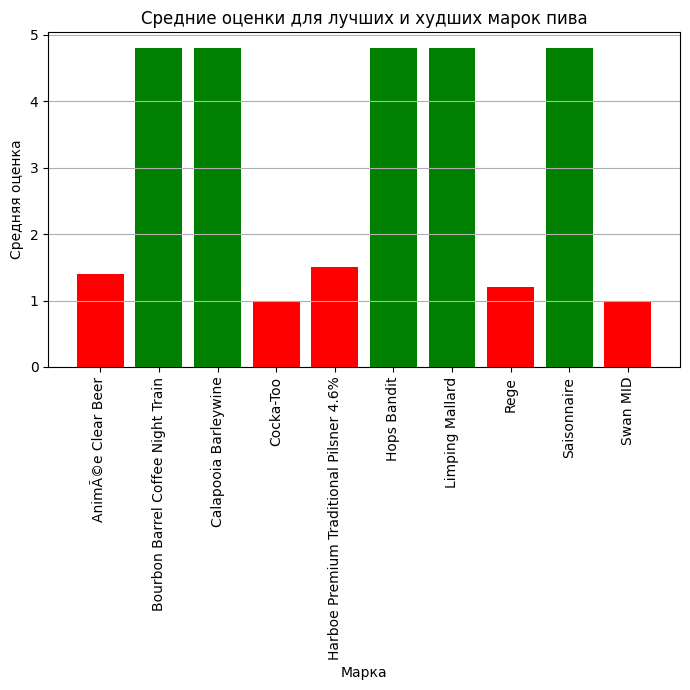

In [26]:
beer_train_only_win_lose_filtered = beer_train_only_win_lose[['beer/name', 'avg_review', 'status']]

# Группировка по статусу, средние значения и стандартное отклонение
summary_stats = beer_train_only_win_lose_filtered.groupby(['beer/name', 'status']).agg(
    mean_avg_review=('avg_review', 'mean'),
    std_avg_review=('avg_review', 'std'),
    count=('avg_review', 'count')
).reset_index()

# Доверительные интервалы
summary_stats['conf_interval'] = 1.96 * (summary_stats['std_avg_review'] / np.sqrt(summary_stats['count']))

# Построение диаграммы + окрашиваем лучшие и худшие марки в зеленый и красный для наглядности
fig, ax = plt.subplots(figsize=(7, 7))
colors = summary_stats['status'].map({'winner': 'green', 'loser': 'red'})

# Столбцы для средних значений
bars = ax.bar(summary_stats['beer/name'], summary_stats['mean_avg_review'], yerr=summary_stats['conf_interval'],
               color=colors, capsize=5)

# Настройка параметров
ax.set_title('Средние оценки для лучших и худших марок пива')
ax.set_xlabel('Марка')
ax.set_ylabel('Средняя оценка')
ax.set_xticks(range(len(summary_stats)))
ax.set_xticklabels(summary_stats['beer/name'], rotation=90)
ax.grid(axis='y')

plt.tight_layout()
plt.show()



Вывод: Доверительные интервалы лучших и худших марок пива не пересекаются, что свидетельствует о статистически значимом различии в оценках. Можем утверждать, что пользователи четко разделяют пиво на "хорошее" и "плохое", средние оценки не являются случайным шумом.

## 4. От чего зависит рейтинг пива?


Проанализируем зависимость целевого признака ``avg_review`` от других признаков.

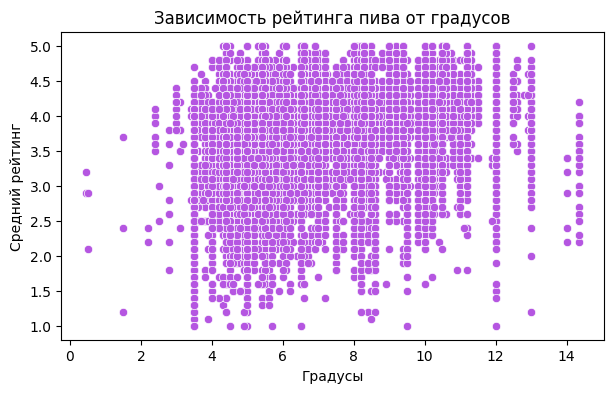

Коэффициент корреляции между avg_review и beer/ABV: 0.38154231074040645


In [27]:
# Визуализация зависимости рейтинга от градусов
plt.figure(figsize=(7, 4))
sns.scatterplot(x='beer/ABV', y='avg_review', data=beer_train, color='#b556e1')
plt.title('Зависимость рейтинга пива от градусов')
plt.xlabel('Градусы')
plt.ylabel('Средний рейтинг')
plt.show()

# Корреляция Пирсона
correlation = beer_train['avg_review'].corr(beer_train['beer/ABV'])
print(f'Коэффициент корреляции между avg_review и beer/ABV: {correlation}')

Корреляция Пирсона составляет ~0.38, что указывает на умеренную положительную связь. Общая тенденция заключается в том, что, чем крепче пиво, тем выше его оценка, однако зависимость не является строго линейной, так как на графике виден широкий "разброс" точек.

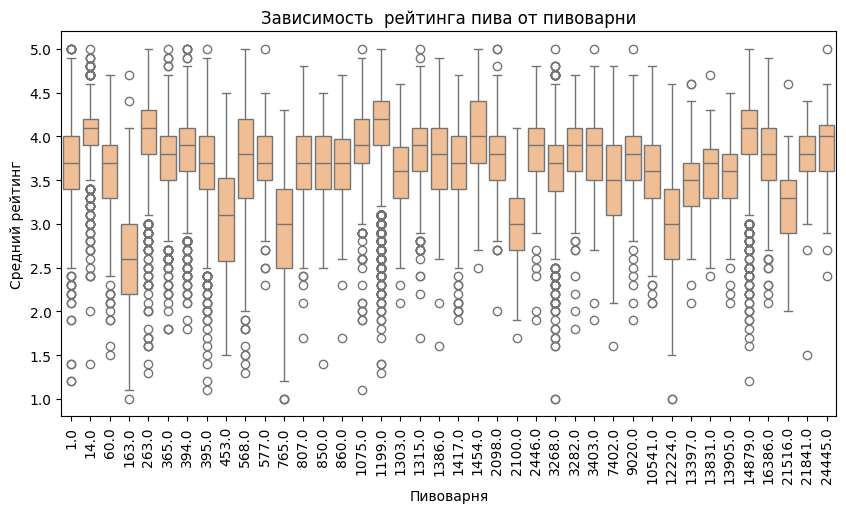

In [28]:
# Визуализация зависимости рейтинга от пивоварни. Их слишком много, поэтому выберем 40 наиболее часто встречающихся и создадим отдельный датафрейм
top_breweries = beer_train['beer/brewerId'].value_counts().nlargest(40).index
filtered_breweries = beer_train[beer_train['beer/brewerId'].isin(top_breweries)]

plt.figure(figsize=(10, 5))
sns.boxplot(x='beer/brewerId', y='avg_review', data=filtered_breweries, color='#ffbc85')
plt.title('Зависимость  рейтинга пива от пивоварни', fontsize=12)
plt.xticks(rotation=90)
plt.xlabel('Пивоварня', fontsize=10)
plt.ylabel('Средний рейтинг', fontsize=10)
plt.show()

Линейной зависимости на графике не выявлено, корреляция между рейтингом пива и пивоварней отсутствует.

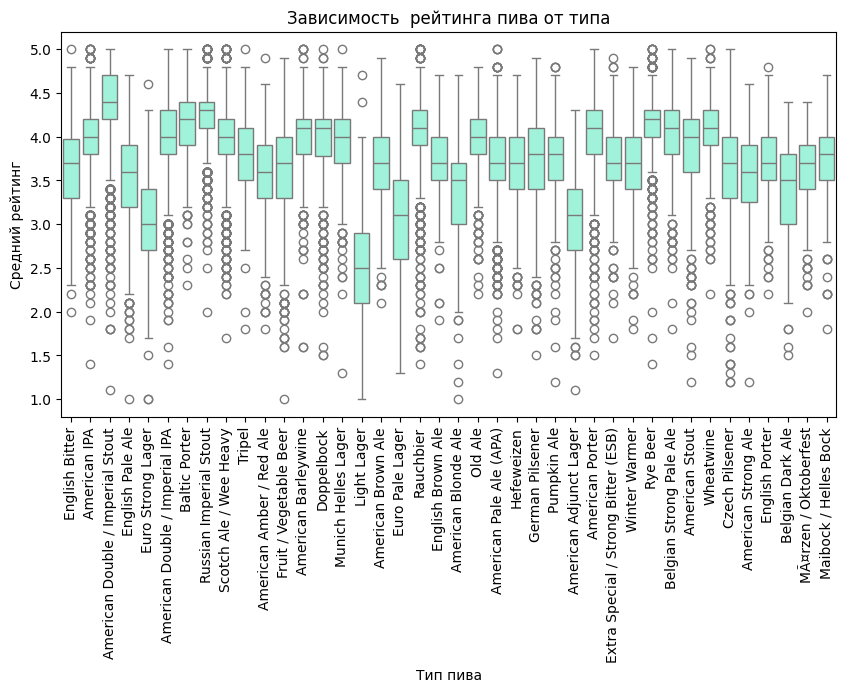

In [29]:
# Визуализация зависимости от типа пива
# Для анализа типов тоже выберем 40 наиболее часто встречающихся и создадим отдельный датафрейм

top_styles = beer_train['beer/style'].value_counts().nlargest(40).index
filtered_styles = beer_train[beer_train['beer/style'].isin(top_styles)]

plt.figure(figsize=(10, 5))
sns.boxplot(x='beer/style', y='avg_review', data=filtered_styles, color='#94ffdf')
plt.title('Зависимость  рейтинга пива от типа', fontsize=12)
plt.xticks(rotation=90)
plt.xlabel('Тип пива', fontsize=10)
plt.ylabel('Средний рейтинг', fontsize=10)
plt.show()

Линейной зависимости на графике не выявлено, корреляция между рейтингом и типом пива отсутствует.

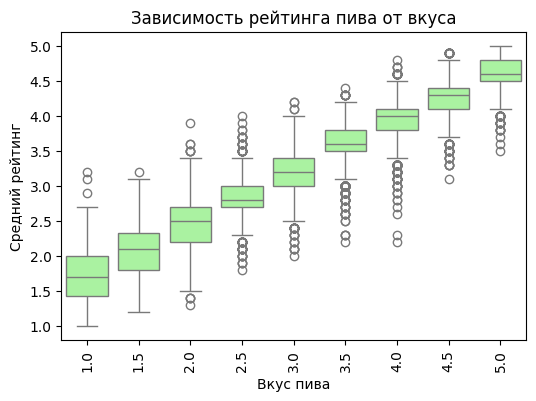

Коэффициент корреляции между avg_review и review/taste: 0.9045369476165444


In [30]:
# Визуализация зависимости от вкуса
plt.figure(figsize=(6, 4))
sns.boxplot(x='review/taste', y='avg_review', data=beer_train, color='#a0ff94')
plt.title('Зависимость рейтинга пива от вкуса')
plt.xticks(rotation=90)
plt.xlabel('Вкус пива')
plt.ylabel('Средний рейтинг')
plt.show()

# Корреляция Пирсона
correlation = beer_train['avg_review'].corr(beer_train['review/taste'])
print(f'Коэффициент корреляции между avg_review и review/taste: {correlation}')

Между итоговым рейтингом и оценкой вкуса существует сильная положительная корреляция (~0.9). Вкус является главным показателем итоговой оценки пива.



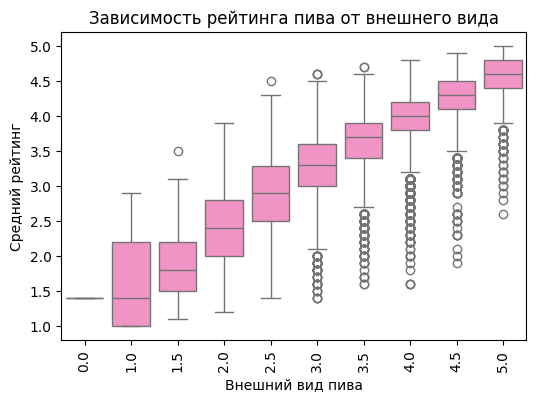

Коэффициент корреляции между avg_review и review/appearance: 0.7281897486350136


In [31]:
# Визуализация зависимости от внешнего вида пива
plt.figure(figsize=(6, 4))
sns.boxplot(x='review/appearance', y='avg_review', data=beer_train, color='#ff85c6')
plt.title('Зависимость рейтинга пива от внешнего вида')
plt.xticks(rotation=90)
plt.xlabel('Внешний вид пива')
plt.ylabel('Средний рейтинг')
plt.show()

# Корреляция Пирсона
correlation = beer_train['avg_review'].corr(beer_train['review/appearance'])
print(f'Коэффициент корреляции между avg_review и review/appearance: {correlation}')

Между рейтингом и внешним видом пива также заметна четкая положительная корреляция (~0.73). Это второй по важности показатель, определяющий оценку пива (после вкуса).

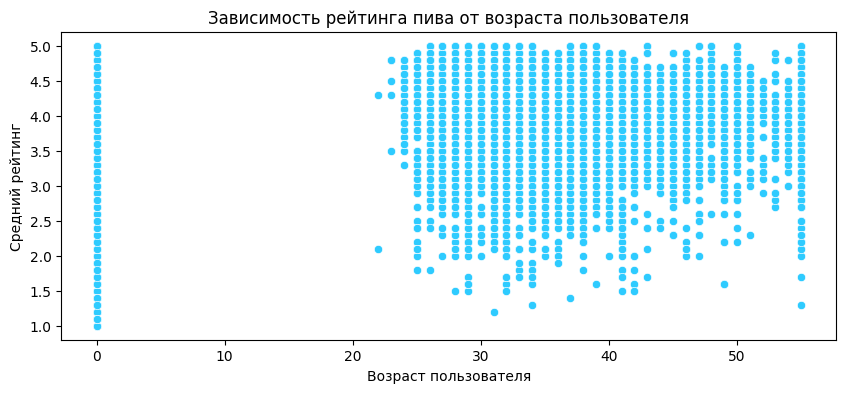

Коэффициент корреляции между avg_review и user/age: 0.007690790909307967


In [32]:
# Визуализация зависимости от возраста пользователя
plt.figure(figsize=(10, 4))
sns.scatterplot(x='user/age', y='avg_review', data=beer_train, color='#2ecbff')
plt.title('Зависимость рейтинга пива от возраста пользователя')
plt.xlabel('Возраст пользователя')
plt.ylabel('Средний рейтинг')
plt.show()

# Корреляция Пирсона
correlation = beer_train['avg_review'].corr(beer_train['user/age'])
print(f'Коэффициент корреляции между avg_review и user/age: {correlation}')

 Корреляция между рейтингом пива и возрастом пользователя не заметна, коэффициент корреляции близок к нулю (~0.008).

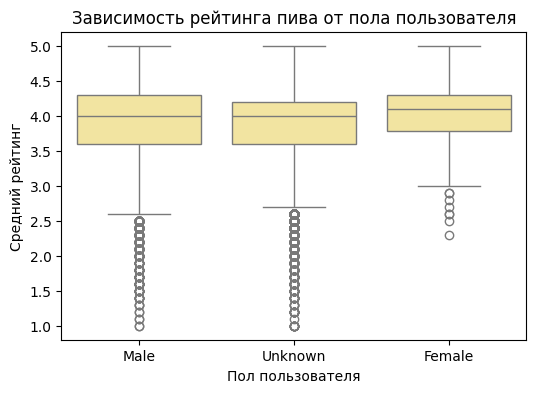

In [33]:
# Визуализация зависимости от пола пользователя
plt.figure(figsize=(6, 4))
sns.boxplot(x='user/gender', y='avg_review', data=beer_train, color='#ffed94')
plt.title('Зависимость рейтинга пива от пола пользователя')
plt.xlabel('Пол пользователя')
plt.ylabel('Средний рейтинг')
plt.show()

Средние значения рейтинга у женщин выше, но не сильно, к тому же выборка не достаточно однородная. Корреляция между рейтингом пива и полом также не заметна.

Вывод: Самая сильная положительная корреляция с общим рейтингом пива наблюдается у оценок вкуса (~ 0.9) и внешнего вида (~ 0.73). Кроме того, заметна умеренная корелляция с крепостью пива (~ 0.38), а корреляция с пивоварней, а также с возрастом и полом пользователя практически отсутствует.

 **Пайплайн для кодирования категорий**  


Категориальные признаки (`beer/brewerId`, `beer/name`, `beer/style`, `user/gender`, `user/profileName`) имеют большое количество уникальных значений. Постараемся объединить их в one-hot признаки для получения более показательных результатов.
1. Применим One-Hot Encoding через `category_encoders`.
2. Затем применим SelectKBest с функцией `f_regression`, чтобы отобрать 10 наиболее информативных признаков (на основе их линейной связи с целевой переменной `avg_review`).

In [34]:
import category_encoders as ce
from sklearn.feature_selection import SelectKBest, f_regression

# Определим целевую переменную и признаки
X_train = beer_train.drop('avg_review', axis=1) #удяляем avg_reveiw, так как это будет целевая переменная
y_train = beer_train['avg_review']
X_test = beer_test.drop('avg_review', axis=1) #присваиваем переменной тестовый датасет

# Создадим one-hot признаки, используя category_encoders
categorical_features = ['beer/brewerId', 'beer/name', 'beer/style', 'user/gender', 'user/profileName']

encoder = ce.OneHotEncoder(cols=categorical_features, use_cat_names=True) #создаем экземпляр класса и указываем нужные столбцы
X_train_encoded = encoder.fit_transform(X_train) #применяем кодировщик для тренировочного набора
X_test_encoded = encoder.transform(X_test) #применяем уже обученный кодировщик для тестового набора

# Отберем лучшие признаки
selector = SelectKBest(score_func=f_regression, k=10)  #выбираем 10 лучших признаков
X_train_selected = selector.fit_transform(X_train_encoded, y_train) #применяем селектор
selected_indices = selector.get_support(indices=True)
selected_feature_names = X_train_encoded.columns[selected_indices]

# Создадим новые датафреймы
X_train_final = X_train_encoded[selected_feature_names]
X_test_final = X_test_encoded[selected_feature_names]

In [35]:
X_train_final

,beer/ABV,beer/brewerId_1199.0,beer/brewerId_163.0,beer/style_American Double / Imperial Stout,beer/style_Light Lager,review/appearance,review/aroma,review/overall,review/palate,review/taste
20254,4.3,0,0,0,0,3.0,3.5,3.0,2.5,3.0
5454,6.5,0,0,0,0,3.5,4.0,3.5,4.0,4.0
24951,7.2,1,0,0,0,3.5,4.0,3.5,3.0,4.0
23548,8.3,1,0,1,0,4.0,5.0,4.5,5.0,4.5
11735,4.7,0,0,0,0,3.5,4.0,4.5,4.0,4.0
...,...,...,...,...,...,...,...,...,...,...
35702,8.2,0,0,0,0,5.0,4.0,5.0,4.0,5.0
26767,4.4,0,0,0,0,4.0,4.5,4.5,4.0,4.5
6618,6.6,0,0,0,0,4.0,4.5,4.0,4.0,4.0
24894,8.2,0,0,0,0,4.0,1.0,1.0,1.0,1.0


In [36]:
X_test_final

,beer/ABV,beer/brewerId_1199.0,beer/brewerId_163.0,beer/style_American Double / Imperial Stout,beer/style_Light Lager,review/appearance,review/aroma,review/overall,review/palate,review/taste
4377,8.3,1,0,1,0,4.0,4.5,4.0,4.0,4.5
11564,9.0,0,0,0,0,4.0,4.0,4.0,4.0,4.5
20724,8.3,1,0,1,0,4.0,5.0,5.0,3.5,5.0
15515,8.3,1,0,1,0,3.5,3.5,3.0,4.0,2.5
21745,8.6,0,0,0,0,4.0,4.0,4.0,4.0,4.5
...,...,...,...,...,...,...,...,...,...,...
23171,3.5,0,1,0,1,2.5,3.0,4.5,4.0,3.5
1853,4.4,0,0,0,0,4.5,4.5,5.0,5.0,5.0
20941,12.0,1,0,0,0,3.5,3.5,3.0,4.0,4.0
28469,11.2,1,0,1,0,5.0,4.5,4.5,5.0,5.0


## Вывод

Алгоритм f_regression отобрал 10 признаков, которые можно использовать для предсказания рейтинга пива. В топ попали числовые признаки (beer/ABV, review/appearance, review/taste и т.д.), так как они имеют самую сильную линейную связь с целевой переменной. Из категориальных признаков в топ попали конкретные пивоварни (beer/brewerId_1199.0) и стили (American Double / Imperial Stout). Это доказывает, что именно стиль и конкретный производитель (наряду с физическими характеристиками пива) сильнее всего влияют на итоговый рейтинг. Пол, возраст или имя пользователя оказались статистически незначимы.